<img src="../assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Clustering with K-Means

---

### About
Understand what unsupervised learning is, when to apply clustering, and perform a k-means clustering, evaluating cluster quality with **inertia** and the **silhouette score**.

### Learning Objectives
- Know the difference between supervised and unsupervised learning.
- Understand when to use clustering.
- Perform a k-means clustering analysis, including scaling and initialisation.
- Evaluate clusters and choose *k* with inertia (the elbow method) and the silhouette score.
- Recognise when k-means is the wrong tool.

### Notebook Guide
| Part | Topic | Data |
|---|---|---|
| — | Unsupervised learning and clustering (reading) | — |
| 1 | How k-means works, step by step | simulated blobs |
| 2 | K-means in scikit-learn | simulated blobs |
| 3 | Why scaling matters | simulated customers |
| 4 | Initialisation and local minima | simulated blobs |
| 5 | Measuring cluster quality: inertia and silhouette | simulated blobs |
| 6 | Choosing *k* | blobs, then the Old Faithful geyser |
| 7 | A real multi-feature dataset | wheat seeds |
| 8 | When k-means struggles | simulated shapes |

Parts 1–4 go with the first guided walkthrough in the slides, Parts 5–8 with the second.


# Unsupervised learning
---
Up until now we've done **supervised learning**: *given X, predict y*. Regression predicts a number; classification predicts a category.

When there's **no y**, we're doing **unsupervised learning**: finding structure in X itself.

| | Supervised | Unsupervised |
|---|---|---|
| Question | "Given X, what is y?" | "What does X look like, really?" |
| Training data | Features **and** answers | Features only |
| How do we judge it? | Compare predictions with the true y | No answer key: metrics, plots and domain knowledge |
| Examples | Linear/logistic regression, k-NN, trees | **Clustering**, dimensionality reduction (PCA) |

### Unsupervised learning creates new issues
- **What is "correct"?** With no y, it's hard to know if we're doing a good job.
- **Tuning.** How do we choose settings (like the number of clusters) without a score to optimise?
- **Interpretation.** The algorithm finds groups; a person has to decide what they *mean*.

# Introduction to Clustering
---
**Clustering** groups observations so that members of the same group are more similar to each other than to members of other groups. "Similar" usually means **close together** in feature space, so the features you choose (and how you scale them) decide what "similar" means.

### Uses for clustering
- **Customer segmentation:** "people in cluster A rarely buy our product: what do they have in common?"
- **Recommender systems:** "customers like you also bought…"
- **Document grouping:** organising news articles or support tickets by topic.
- **Anomaly detection:** points far from every cluster centre are worth a look.
- **Feature engineering:** adding a "cluster" column as a new feature for a supervised model.

### Recommender Systems Example
Online retailers cluster their items by similarity. If you buy (or search for) a few items in a given cluster, they may recommend you other similar items in that same cluster.

![](../assets/recs.png)


### Clustering algorithms
There are many: **k-means** (today), **DBSCAN** (density-based) and **hierarchical clustering**, plus Gaussian mixtures, mean shift and more. There are so many because "a cluster" has no single definition.

These algorithms nearly always reduce to difficult optimization problems which may converge on a local minimum (similarly to gradient descent).

- **K-Means** (mean centroids)
- **DBSCAN** (density based)
- **Hierarchical** (nested clusters by merging or splitting successively)
- **Affinity Propagation** (graph based approach to let points 'vote' on their preferred 'exemplar')
- **Mean Shift** (can find number of clusters)
- **Spectral Clustering**
- **Agglomerative Clustering** (suite of algorithms all based on applying the same criteria/characteristics of one cluster to others)


Image from scikit-learn: ["Comparing different clustering algorithms on toy datasets."](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html)

![](../assets/sklearn-clustering.png)

k-means is fast and simple, but it can only make **convex** (roughly round, "blob-shaped") clusters, and it may need several runs to find a good answer. Part 8 shows where that matters.


# K-Means Clustering
---
- **k** = the number of clusters (you choose it in advance).
- **Means** = each cluster's centre (**centroid**) is the mean of its points.

### The algorithm
1. Choose *k*.
2. Place *k* starting centroids.
3. **Assign** every point to its nearest centroid.
4. **Update** each centroid to the mean of its assigned points.
5. Repeat steps 3–4 until nothing changes.

k-means is minimising **inertia**: the total squared distance from each point to its centroid. Each step can only lower it, so the algorithm always stops, but possibly at a **local** minimum that depends on the starting centroids (Part 4).

# Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

# Part 1: How k-means works, step by step
---
Let's run the algorithm "by hand" on simulated data with three blobs, starting from three deliberately poor centroids (all along the bottom edge), and watch the **assign → update** loop.

In [ ]:
data, true_blob = make_blobs(n_samples=150, centers=3, cluster_std=1.2, random_state=42)
centroids = np.array([[-8.0, -9.0], [-5.0, -9.0], [6.0, -9.0]])     # a poor start: all along the bottom edge

In [3]:
data.shape

(150, 2)

In [4]:
data

array([[ -2.55218887,  10.89185852],
       [ -3.51625865,   8.64323128],
       [ -6.54243695,  -7.62734902],
       [  6.90330192,   2.18266306],
       [ -6.26158487,  -6.26356645],
       [  5.39067965,   0.94458062],
       [ -3.32150402,   9.74829767],
       [ -3.07256689,   9.66535818],
       [ -7.44594543,  -5.57336888],
       [  3.62372637,   0.15535301],
       [ -4.33303975,  -5.64115128],
       [ -7.18270897,  -8.37744941],
       [  4.59822471,   0.57075604],
       [ -6.74340638,  -6.08555278],
       [  3.47026083,   2.91767121],
       [ -4.20764251,   8.50951174],
       [ -6.64075556,  -7.60036985],
       [ -2.50306148,   8.73278157],
       [  4.94047026,   2.38890754],
       [  2.77908272,   2.05544525],
       [ -3.16245689,   9.14739324],
       [ -7.44956156,  -7.66410467],
       [  4.37172349,   2.82997028],
       [ -4.30689428,  -6.11940677],
       [  3.35480784,   2.55213658],
       [ -8.39268794,  -5.77867526],
       [ -6.27364246,  -5.84120336],
 

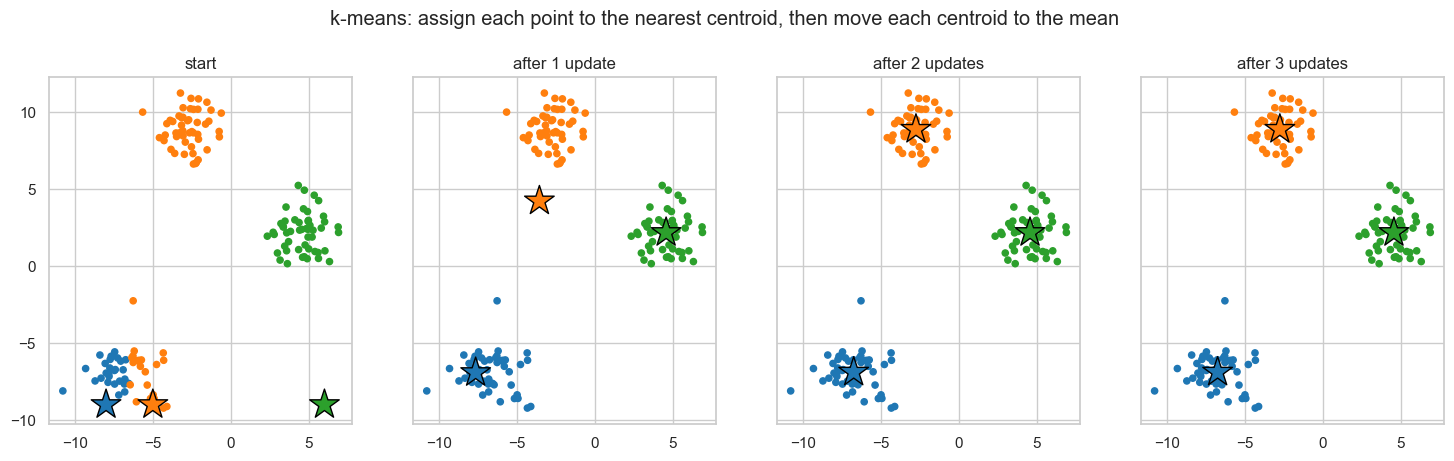

In [5]:

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharex=True, sharey=True)
for step, ax in enumerate(axes):
    # ASSIGN: each point goes to its nearest centroid
    distances = np.linalg.norm(data[:, None, :] - centroids[None, :, :], axis=2)
    # in this case np.linalg.norm with the parameters used is creating a 2D array 
    # where each row corresponds to a data point and each column corresponds to a centroid.
    # The value at (i, j) is the distance from data point i to centroid j. 
    # The argmin function then finds the index of the nearest centroid for
    # each data point, effectively assigning each point to the closest centroid.
    labels = distances.argmin(axis=1)
    ax.scatter(data[:, 0], data[:, 1], c=labels, cmap='tab10', vmin=0, vmax=9, s=20)
    ax.scatter(centroids[:, 0], centroids[:, 1], c=[0, 1, 2], cmap='tab10', vmin=0, vmax=9,
               marker='*', s=500, edgecolor='black')
    ax.set_title('start' if step == 0 else f'after {step} update{"s" if step > 1 else ""}')
    # now move each centroid to the mean of its points
    centroids = np.array([data[labels == k].mean(axis=0) for k in range(3)])
plt.suptitle('k-means: assign each point to the nearest centroid, then move each centroid to the mean', y=1.03);

Even from a poor start, the centroids move to the centres of the three blobs within a couple of rounds, and then stop changing: the algorithm has **converged**. That loop is all k-means is. Everything else is about **choosing k**, **scaling**, **starting well** (not every start ends this well: see Part 4) and **checking the result**.

# Part 2: K-means in `scikit-learn`
---

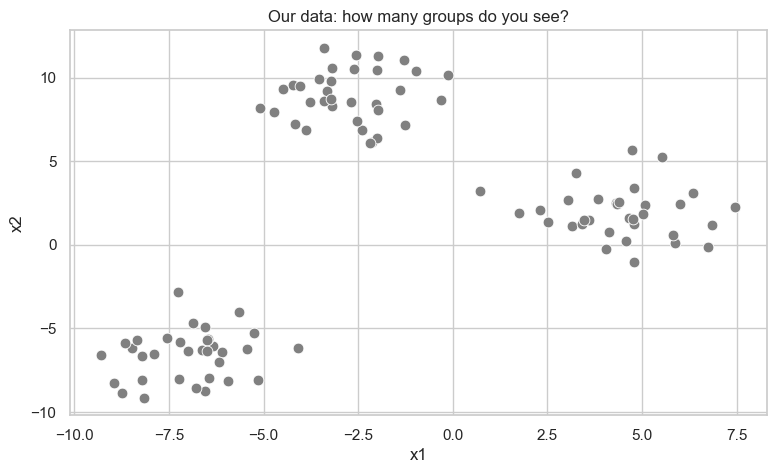

In [6]:
data, color = make_blobs(n_samples=100, random_state=42, centers=3, cluster_std=1.5)
df = pd.DataFrame(data, columns=['x1', 'x2'])
sns.scatterplot(data=df, x='x1', y='x2', s=60, color='grey')
plt.title('Our data: how many groups do you see?');

### A VERY important step before fitting: scaling
k-means uses distances, so features must be on comparable scales (Part 3 shows why).

In [7]:
X = df[['x1', 'x2']]
sc = StandardScaler()
X_scaled = sc.fit_transform(X)

km = KMeans(n_clusters=3, n_init=10, random_state=42)     # n_init: run 10 times, keep the best
km.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[-0.

### I. Cluster labels

In [8]:
df['cluster'] = km.labels_            # same as km.predict(X_scaled)
df.head()

,x1,x2,cluster
0,-8.149818,-9.152380,1
1,5.860155,0.126873,2
2,-3.213409,9.828126,0
3,6.744070,-0.129607,2
4,-6.342946,-6.038933,1


### II. Centroids

In [9]:
# Option 1: the mean of each cluster, in the original units
df.groupby('cluster')[['x1', 'x2']].mean().round(2)

,x1,x2
cluster,,
0,-2.75,8.90
1,-6.99,-6.57
2,4.43,1.92


In [10]:
# Option 2: the model's centroids... but these are in SCALED units!
km.cluster_centers_.round(2)

array([[-0.2 ,  1.14],
       [-1.07, -1.24],
       [ 1.28,  0.07]])

In [11]:
# Remember, we scaled! Convert back with inverse_transform: now it matches Option 1
centroids = pd.DataFrame(sc.inverse_transform(km.cluster_centers_), columns=['x1', 'x2'])
centroids.round(2)

,x1,x2
0,-2.75,8.90
1,-6.99,-6.57
2,4.43,1.92


### Visually verifying the clusters

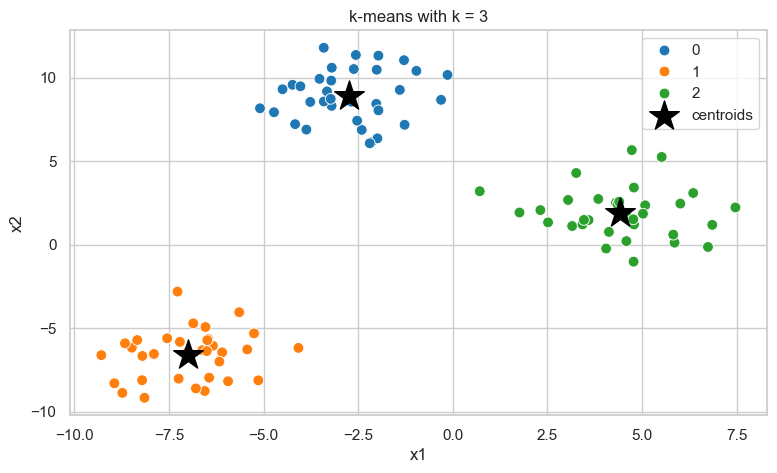

In [12]:
sns.scatterplot(data=df, x='x1', y='x2', hue='cluster', palette='tab10', s=60)
plt.scatter(centroids['x1'], centroids['x2'], marker='*', s=500, c='black', label='centroids')
plt.legend(); plt.title('k-means with k = 3');

# Part 3: Why scaling matters
---
Imagine customers described by **age** (in years) and **income** (in dollars). The data has three real groups. Without scaling, income differences are measured in tens of thousands while age differences are in tens, so **income completely dominates the distances**.

(Because this data is simulated, we know the true groups, so we can score each clustering with the **adjusted Rand index (ARI)**: 1 = perfect match with the true groups, 0 = no better than chance.)

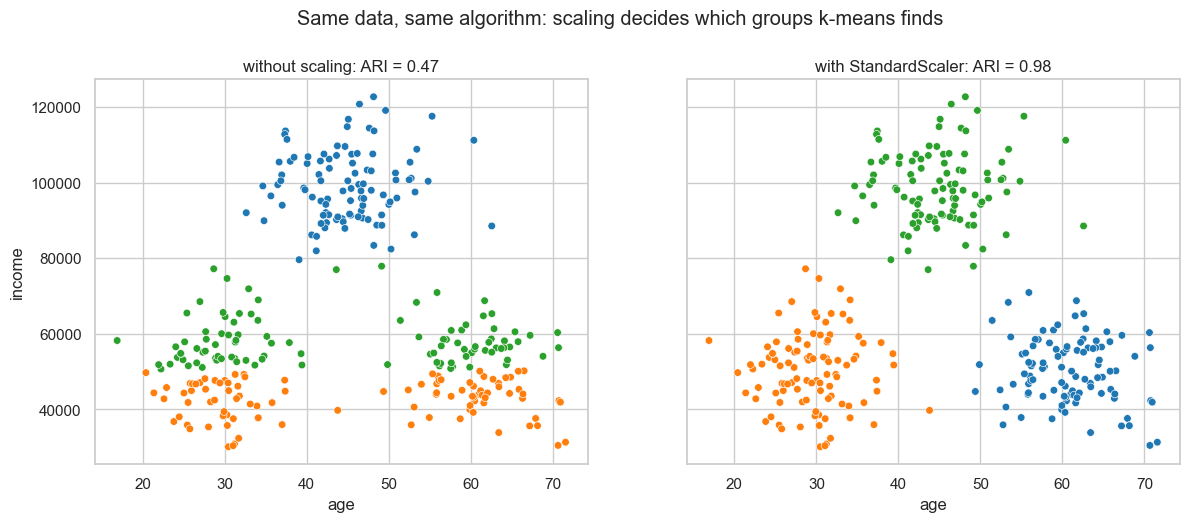

In [13]:
pts, true_group = make_blobs(n_samples=300, centers=[(0, 0), (6, 0), (3, 5)], cluster_std=1.0, random_state=42)
customers = pd.DataFrame({'age': 30 + 5 * pts[:, 0], 'income': 50000 + 10000 * pts[:, 1]})

unscaled = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(customers)
scaled = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(StandardScaler().fit_transform(customers))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, labels, name in [(axes[0], unscaled, 'without scaling'), (axes[1], scaled, 'with StandardScaler')]:
    sns.scatterplot(x=customers['age'], y=customers['income'], hue=labels, palette='tab10', ax=ax, legend=False, s=30)
    ax.set_title(f'{name}: ARI = {adjusted_rand_score(true_group, labels):.2f}')
plt.suptitle('Same data, same algorithm: scaling decides which groups k-means finds', y=1.02);

Unscaled, k-means slices the data into **horizontal income bands** and ignores age. Scaled, it finds the three real groups.

# Part 4: Initialisation and local minima
---
k-means always converges, but **where** it ends up depends on the starting centroids. With one random start, it can get stuck in a poor solution (a **local minimum**). Here are three single runs with random starts on data with six blobs:

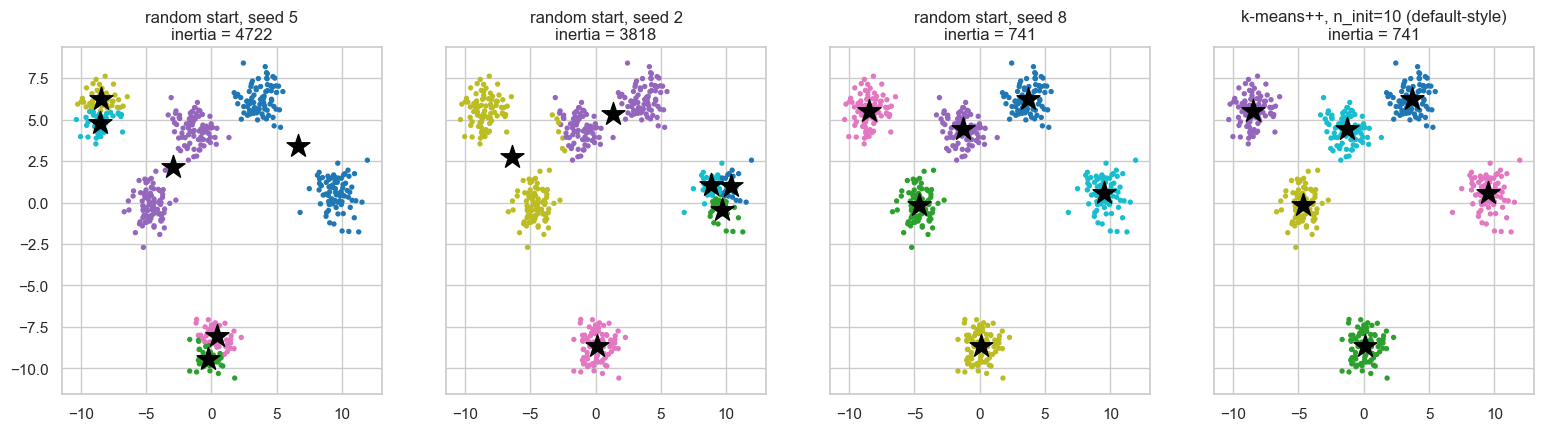

In [ ]:
X6, _ = make_blobs(n_samples=500, centers=6, cluster_std=0.9, random_state=7)
fig, axes = plt.subplots(1, 4, figsize=(19, 4.5), sharex=True, sharey=True)
runs = [('random start, seed 5', dict(init='random', n_init=1, random_state=5)),
        ('random start, seed 2', dict(init='random', n_init=1, random_state=2)),
        ('random start, seed 8', dict(init='random', n_init=1, random_state=8)),
        ('k-means++, n_init=10 (default-style)', dict(n_init=10, random_state=0))]
for ax, (name, kwargs) in zip(axes, runs): 
# the zip function is used to iterate over two or more iterables (like lists or tuples)
# in parallel. In this case, it pairs each axis (ax) from the axes array with a corresponding
# tuple (name, kwargs) from the runs list. This allows the loop to access both the plotting
# axis and the specific configuration for each KMeans run in a single iteration.
    model = KMeans(n_clusters=6, **kwargs).fit(X6)
    ax.scatter(X6[:, 0], X6[:, 1], c=model.labels_, cmap='tab10', s=8)
    ax.scatter(*model.cluster_centers_.T, marker='*', s=300, c='black')
    ax.set_title(f'{name}\ninertia = {model.inertia_:.0f}')

The bad runs merge two blobs and split another: their inertia is several times higher. Two defences, both built into scikit-learn:
- **k-means++** initialisation (the default) spreads the starting centroids out.
- **`n_init`** runs the whole algorithm several times and keeps the lowest-inertia result. (In recent scikit-learn versions the default is a single run with k-means++, so set `n_init=10` for more reliable results.)

Always set `random_state` too, so your results are repeatable.

# Part 5: Measuring cluster quality
---
## Inertia (within-cluster sum of squares)
The total squared distance from every point to its own cluster's centroid:

$$\text{inertia} = \sum_{k=1}^{K} \sum_{x_i \in \text{cluster } k} \lVert x_i - \mu_k \rVert^2$$

where $\mu_k$ is the centroid of cluster $k$. **Lower = tighter clusters.** Here's the example from the slides:

In [15]:
points = np.array([[6, 10], [7, 8], [1, 5], [6, 5]])
centroid = points.mean(axis=0)
print('centroid:', centroid)                                      # (5, 7)
print('squared distances:', ((points - centroid) ** 2).sum(axis=1))  # 10, 5, 20, 5
print('inertia:', ((points - centroid) ** 2).sum())               # 40

centroid: [5. 7.]
squared distances: [10.  5. 20.  5.]
inertia: 40.0


And for our blobs, the same calculation matches scikit-learn's `inertia_`:

In [16]:
by_hand = sum(((X_scaled[km.labels_ == k] - km.cluster_centers_[k]) ** 2).sum() for k in range(3))
print(f'by hand: {by_hand:.3f} | km.inertia_: {km.inertia_:.3f}')

by hand: 12.265 | km.inertia_: 12.265


## Silhouette score
For each point $i$:
- $a_i$ (**cohesion**) = average distance from point $i$ to the other points in **its own** cluster;
- $b_i$ (**separation**) = average distance from point $i$ to the points in the **nearest other** cluster;

$$s_i = \frac{b_i - a_i}{\max(a_i, b_i)}$$

$s_i$ near **1** = well inside its cluster; near **0** = on the border between clusters; **negative** = probably in the wrong cluster. The silhouette score is the average over all points.

In [17]:
print(f'silhouette score (k = 3): {silhouette_score(X_scaled, km.labels_):.3f}')

silhouette score (k = 3): 0.772


### The Silhouette Plot
Plotting every point's $s_i$, grouped by cluster, shows **which** clusters are solid. Compare the right number of clusters (3) with too many (5):

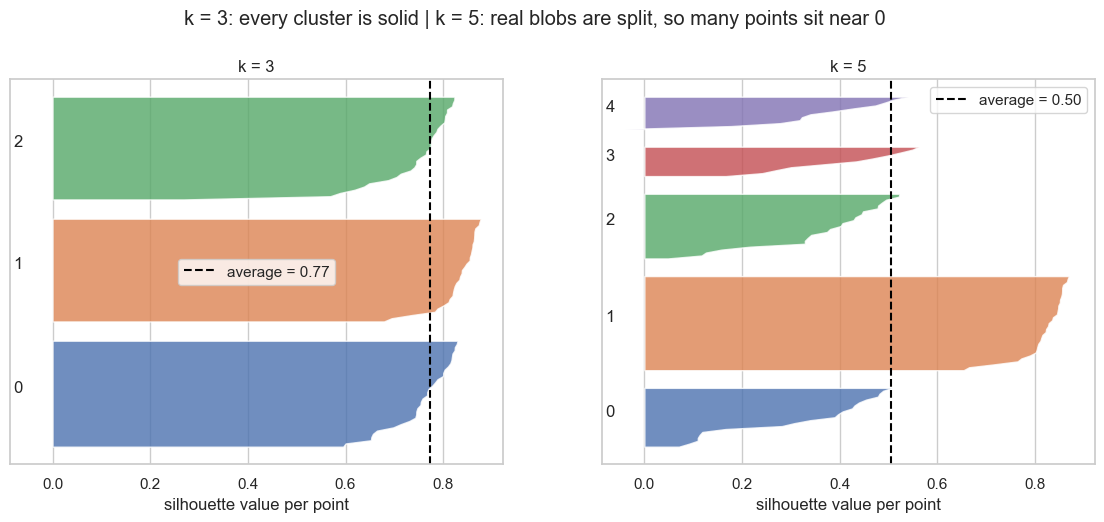

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, k in zip(axes, [3, 5]):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    s = silhouette_samples(X_scaled, labels)
    y0 = 0
    for c in range(k):
        vals = np.sort(s[labels == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, alpha=0.8)
        ax.text(-0.08, y0 + len(vals) / 2, str(c))
        y0 += len(vals) + 5
    ax.axvline(s.mean(), color='black', ls='--', label=f'average = {s.mean():.2f}')
    ax.set_title(f'k = {k}'); ax.set_xlabel('silhouette value per point'); ax.set_yticks([]); ax.legend()
plt.suptitle('k = 3: every cluster is solid | k = 5: real blobs are split, so many points sit near 0', y=1.02);

# Part 6: Choosing *k*
---
There's no answer key, so we combine:
- **business needs** ("marketing can handle 4 segments");
- **the elbow method:** plot inertia against k and look for where adding clusters stops helping much (inertia *always* falls as k grows, so don't just pick the minimum);
- **the silhouette score:** higher is better;
- **looking at the clusters** and asking whether they make sense.

A helper function to plot both metrics side by side:

,k,inertia,silhouette
0,1,200.000,NaN
1,2,67.929,0.646
2,3,12.265,0.772
3,4,10.454,0.620
4,5,8.873,0.505
5,6,7.277,0.355
6,7,6.362,0.361
7,8,5.478,0.358
8,9,4.807,0.376
9,10,4.267,0.359


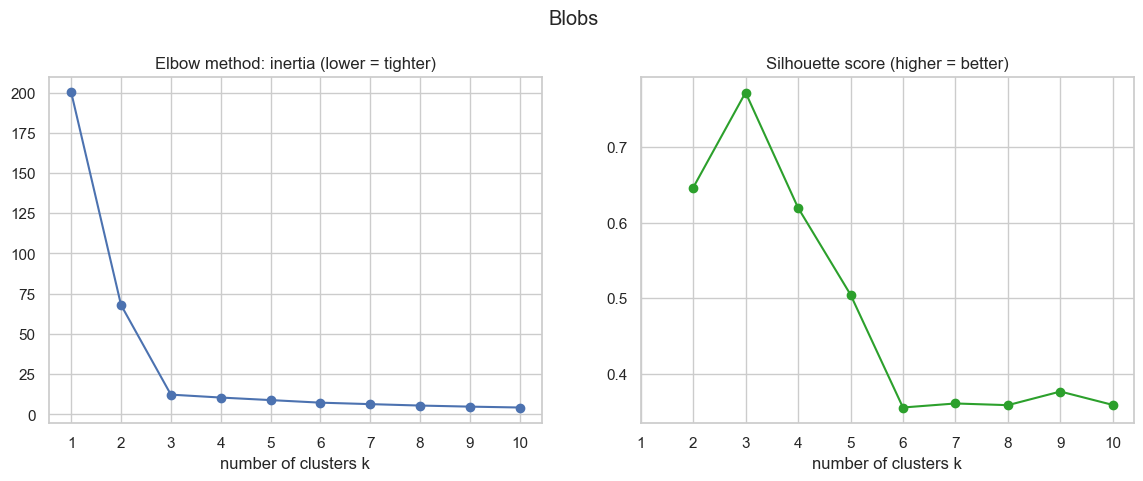

In [19]:
def choose_k(X, k_values=range(1, 11), title=''):
    inertia, silhouette = [], []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        inertia.append(model.inertia_)
        silhouette.append(silhouette_score(X, model.labels_) if k > 1 else np.nan)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(list(k_values), inertia, marker='o'); axes[0].set_title('Elbow method: inertia (lower = tighter)')
    axes[1].plot(list(k_values), silhouette, marker='o', color='tab:green'); axes[1].set_title('Silhouette score (higher = better)')
    for ax in axes: ax.set_xlabel('number of clusters k'); ax.set_xticks(list(k_values))
    plt.suptitle(title, y=1.03)
    return pd.DataFrame({'k': list(k_values), 'inertia': inertia, 'silhouette': silhouette}).round(3)

choose_k(X_scaled, title='Blobs')

For the blobs, both methods agree: **k = 3** (the elbow, and the highest silhouette).

## Real data: the Old Faithful geyser
Each row is one eruption of the Old Faithful geyser in Yellowstone: how long it lasted (`duration`, minutes) and the wait until the next one (`waiting`, minutes). Can clustering find structure?

(272, 2)


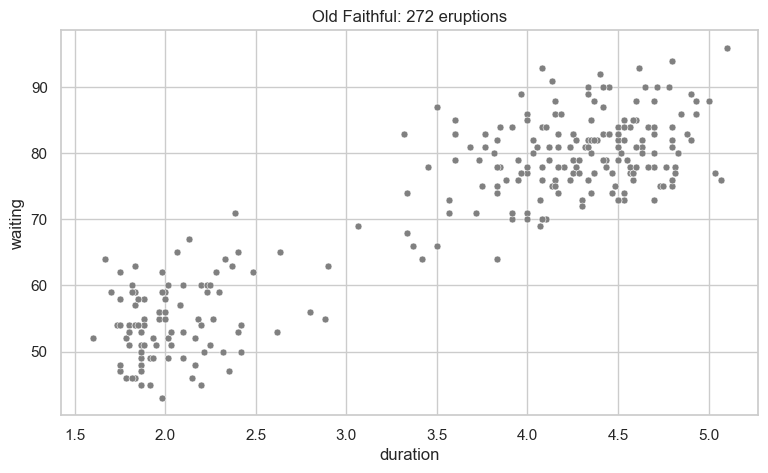

In [20]:
geyser = pd.read_csv('../data/geyser.csv')
print(geyser.shape)
sns.scatterplot(data=geyser, x='duration', y='waiting', color='grey', s=25)
plt.title('Old Faithful: 272 eruptions');

,k,inertia,silhouette
0,1,544.000,NaN
1,2,79.576,0.745
2,3,56.314,0.485
3,4,43.871,0.382
4,5,34.274,0.363
5,6,27.284,0.392
6,7,23.846,0.392
7,8,20.845,0.358
8,9,18.752,0.352
9,10,17.008,0.351


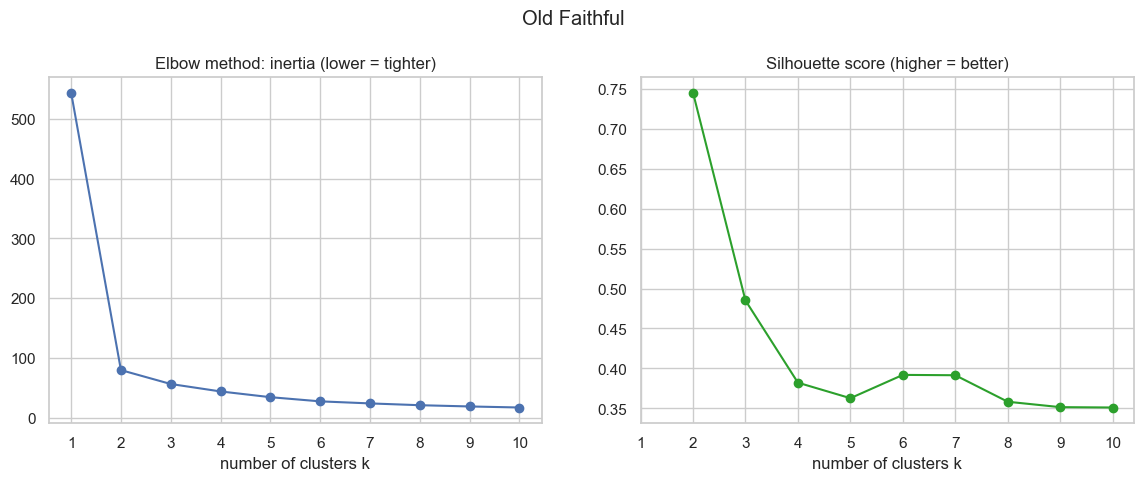

In [21]:
Xg = StandardScaler().fit_transform(geyser[['duration', 'waiting']])
choose_k(Xg, title='Old Faithful')

Both point to **k = 2**: a sharp elbow and the highest silhouette.

        duration       waiting      
            mean count    mean count
cluster                             
0            4.3   174    80.1   174
1            2.1    98    54.6    98


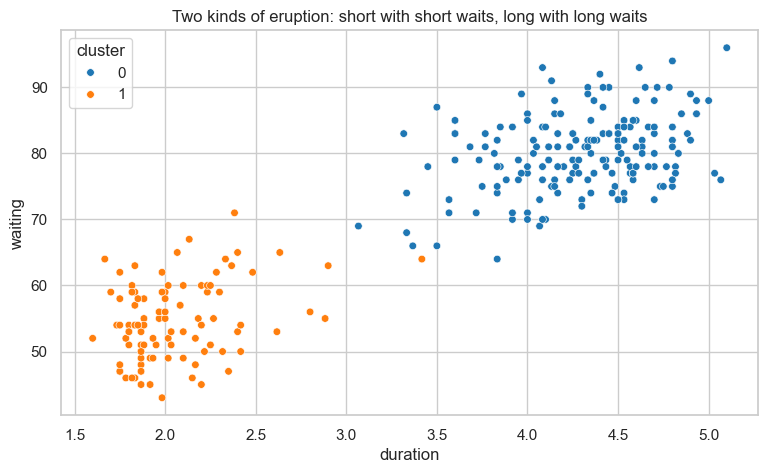

In [22]:
km_g = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xg)
geyser['cluster'] = km_g.labels_
print(geyser.groupby('cluster')[['duration', 'waiting']].agg(['mean', 'count']).round(1))
sns.scatterplot(data=geyser, x='duration', y='waiting', hue='cluster', palette='tab10', s=30)
plt.title('Two kinds of eruption: short with short waits, long with long waits');

Interpretation is the human part: **short eruptions (about 2 minutes) are followed by short waits (about 55 minutes); long eruptions (about 4.3 minutes) by long waits (about 80 minutes).** Park rangers use exactly this pattern to predict the next eruption.

# Part 7: A real multi-feature dataset: wheat seeds
---
Seven measurements of 210 wheat kernels (area, perimeter, compactness, length, width, asymmetry, groove length) from three varieties.

We'll **hide** the variety while clustering, then use it to check how well k-means did, something we can rarely do in real clustering.

In [36]:
seeds = pd.read_csv('../data/seeds.csv')
print(seeds.shape)
print(f'3 groups of 70: {seeds["species"].value_counts().sort_index().to_dict()}')
seeds.head()

(210, 8)
3 groups of 70: {1: 70, 2: 70, 3: 70}


,area,perimeter,compactness,length,width,asymmetry_coeff,groove_length,species
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


,k,inertia,silhouette
0,1,1470.000,NaN
1,2,659.172,0.466
2,3,430.659,0.401
3,4,371.302,0.328
4,5,326.514,0.285
5,6,289.804,0.280
6,7,262.974,0.271
7,8,240.643,0.251


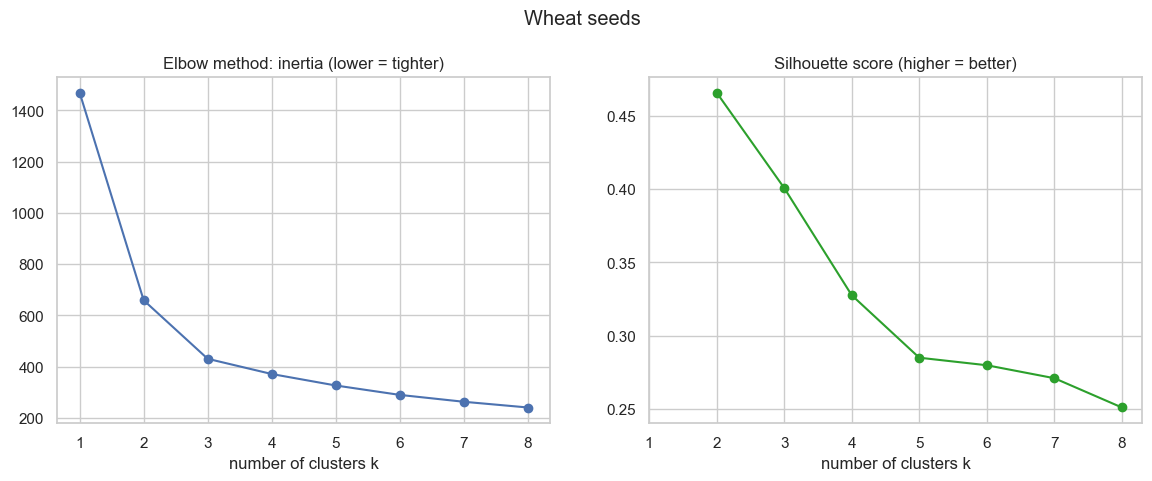

In [24]:
features = seeds.drop(columns='species')
Xs = StandardScaler().fit_transform(features)      # the features have very different spreads
choose_k(Xs, range(1, 9), title='Wheat seeds')

**The metrics disagree.** The elbow suggests **3**, while the silhouette prefers **2**. This happens a lot with real data: two of the varieties overlap, so "two groups" looks tidier to the silhouette.

Domain knowledge (three varieties were grown) tips the decision to **k = 3**.

Agreement with the true varieties (ARI): 0.773


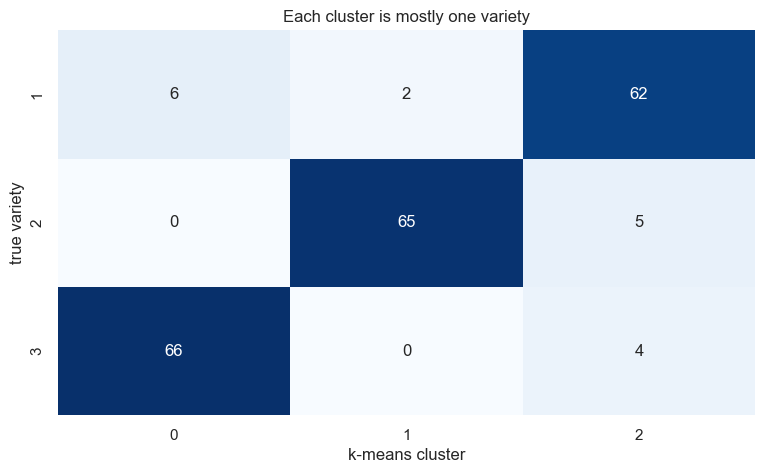

In [25]:
km_s = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xs)
seeds['cluster'] = km_s.labels_
print(f'Agreement with the true varieties (ARI): {adjusted_rand_score(seeds["species"], seeds["cluster"]):.3f}')

sns.heatmap(pd.crosstab(seeds['species'], seeds['cluster']), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('k-means cluster'); plt.ylabel('true variety'); plt.title('Each cluster is mostly one variety');

Cluster numbers are arbitrary (cluster 0 isn't variety 1); what matters is that each cluster is mostly one variety. A few kernels sit between varieties and land in the "wrong" cluster.


### Seeing it: two features, true varieties vs clusters

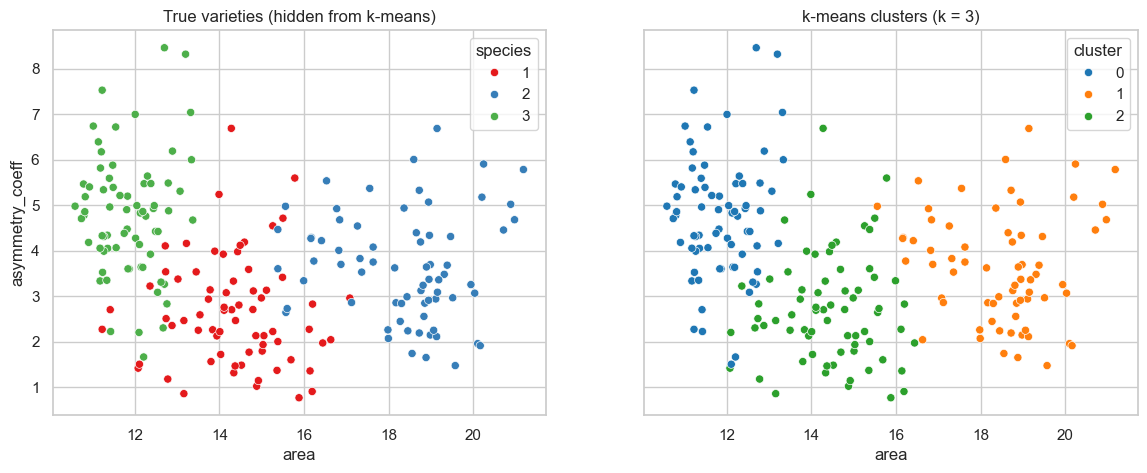

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.scatterplot(data=seeds, x='area', y='asymmetry_coeff', hue='species', palette='Set1', ax=axes[0], s=35)
sns.scatterplot(data=seeds, x='area', y='asymmetry_coeff', hue='cluster', palette='tab10', ax=axes[1], s=35)
axes[0].set_title('True varieties (hidden from k-means)'); axes[1].set_title('k-means clusters (k = 3)');

### Interpreting clusters: profiles
Clustering is only useful once you can **describe** each cluster. Compare each cluster's average (in standard deviations from the overall mean) for every feature:

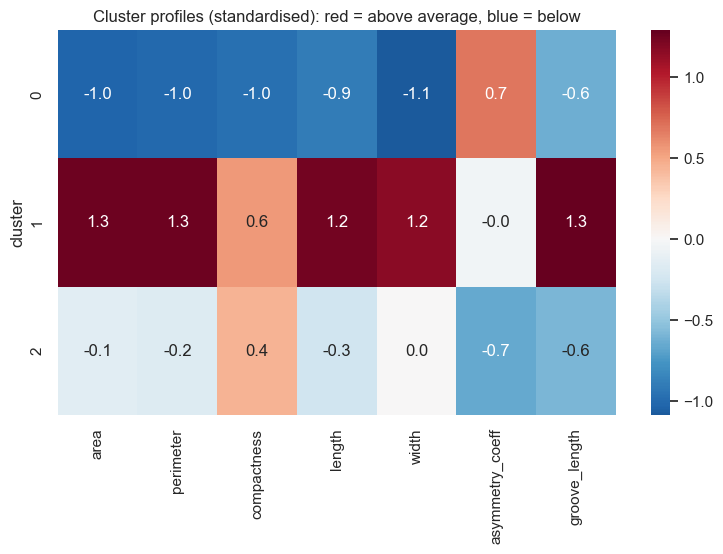

In [27]:
profile = pd.DataFrame(km_s.cluster_centers_, columns=features.columns)
sns.heatmap(profile, annot=True, fmt='.1f', cmap='RdBu_r', center=0)
plt.ylabel('cluster'); plt.title('Cluster profiles (standardised): red = above average, blue = below');

For example, one cluster has large, long kernels; another small kernels with high asymmetry. Descriptions like these are what you'd hand to a stakeholder.


# Part 8: When k-means struggles
---
k-means assumes clusters are roughly **round**, of **similar spread**, and that *k* is right. When the data breaks those assumptions, it still returns k groups, just the wrong ones:

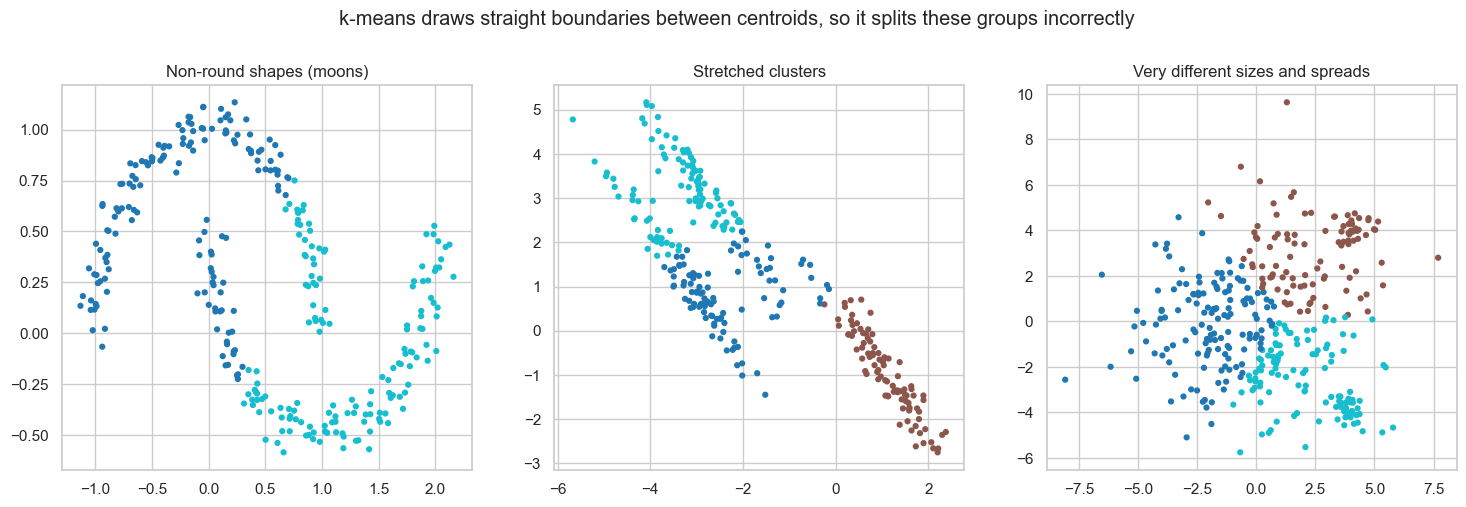

In [37]:
moons_X, _ = make_moons(n_samples=300, noise=0.06, random_state=42)
stretched_X, _ = make_blobs(n_samples=300, centers=3, random_state=170)
stretched_X = stretched_X @ np.array([[0.6, -0.64], [-0.41, 0.85]])           # stretch the blobs
uneven_X, _ = make_blobs(n_samples=[300, 30, 30], centers=[(0, 0), (4, 4), (4, -4)],
                         cluster_std=[2.5, 0.4, 0.4], random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (Xp, k, title) in zip(axes, [(moons_X, 2, 'Non-round shapes (moons)'),
                                      (stretched_X, 3, 'Stretched clusters'),
                                      (uneven_X, 3, 'Very different sizes and spreads')]):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xp)
    ax.scatter(Xp[:, 0], Xp[:, 1], c=labels, cmap='tab10', s=12)
    ax.set_title(title)
plt.suptitle('k-means draws straight boundaries between centroids, so it splits these groups incorrectly', y=1.03);

Density-based methods (**DBSCAN**) and **hierarchical clustering** handle shapes like these better.

### Metrics can mislead too
Uniform random noise has **no** clusters at all, but k-means still splits it, and the silhouette score doesn't look alarming:

In [29]:
noise = np.random.default_rng(0).uniform(0, 1, (300, 2))
for k in [2, 3, 4]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(noise)
    print(f'k = {k}: silhouette on pure noise = {silhouette_score(noise, labels):.3f}')

k = 2: silhouette on pure noise = 0.359
k = 3: silhouette on pure noise = 0.379
k = 4: silhouette on pure noise = 0.400


A silhouette around 0.4 on pure noise is a reminder: **always look at your clusters and ask whether they make sense**, not just at the score.

# Conclusions and Takeaways
---
- **Unsupervised learning** finds structure without a y; a person must interpret the result.
- **k-means** repeats *assign to the nearest centroid → move each centroid to the mean* until it stops.
- **Scale your features**, set **`n_init`** and **`random_state`**.
- **Inertia** always falls as k grows: look for the elbow. **Silhouette**: higher is better, but it can disagree with the elbow and can look fine on noise.
- Choose *k* with metrics **plus** domain knowledge, then **profile** the clusters so they mean something.
- k-means assumes round clusters of similar size; check visually and reach for DBSCAN or hierarchical clustering when it doesn't fit.

### Questions
<details><summary>What's the main difference between supervised and unsupervised learning?</summary>

Supervised learning has a target (y) to predict and an answer key to score against; unsupervised learning has only features and looks for structure in them.
</details>

<details><summary>Why must we scale before k-means?</summary>

k-means uses distances, so features with large numbers (like income in dollars) dominate and the others are ignored (Part 3).
</details>

<details><summary>Why might two runs of k-means give different clusters?</summary>

It can converge to different local minima from different starting centroids (Part 4). Use k-means++ and `n_init` to keep the best of several runs.
</details>

<details><summary>What does the silhouette score measure?</summary>

How much closer each point is to its own cluster than to the nearest other cluster, averaged over all points: near 1 = dense, well-separated clusters; near 0 = overlapping clusters; negative = misassigned points.
</details>

## Further reading
- The [scikit-learn clustering guide](https://scikit-learn.org/stable/modules/clustering.html) compares many algorithms, with pictures.
- scikit-learn's ["Demonstration of k-means assumptions"](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_assumptions.html) shows the cases in Part 8.